# Plot SnFR stimulus-duration traces from HDF5

Reads the HDF5 file made by `organize_snfr_to_hdf5` and makes these trace plots:
- **Section 6a:** conditions overlaid for one stimulus duration (`plot_csv_genotypes_overlay_stimstyle`).
- **Section 6b:** one panel per stimulus duration, conditions overlaid, with each condition's color lighter for shorter durations (`plot_csv_genotypes_overlay_all_stim_durations`).

Processing (sections 3 to 5):
- each neuron's trace is cut after its last valid value, gets a time axis from the imaging frequency of that recording, is low-pass filtered at that imaging frequency (zero-phase Butterworth; the cutoff is set with `lowpass_cutoff_hz`, 4 Hz by default), and the nearest filtered sample is taken at each point of a common time grid (`grid_step`, 20 ms by default). There is no binning or averaging in this step,
- all neurons from all flies of a condition, sensor and duration are pooled, and the mean and SEM are taken at each time point,
- in 6b, the mean and SEM are smoothed for display only (`apply_smoothing`, `smooth_wid`). `smooth_wid` counts grid points, so with the 20 ms grid `smooth_wid=3` averages over 60 ms.

Data loading: `load_files_df_from_hdf5` reads the HDF5 file into a table with one row per recording (`files_df`), and `read_response_csv` returns the traces of one recording.

**Choosing what to plot:** in section 6, set the experiment (`iglusnfr` or `iachsnfr`) and, optionally, the compartment(s). The `ca` recordings of the two experiments are kept apart this way. Leaving `COMPARTMENTS = None` pools all compartments of the experiment.

**How to use:** set `H5_FILE` in section 1, then run all cells.

In [2]:
import re
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import gridspec
from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from scipy.signal import butter, sosfiltfilt

## 1. Settings

In [41]:
H5_FILE = Path("your/path/here/snfr.h5")

In [42]:
# Line colors per condition.
genotype_colors = {
    "CTR": "#4d4d4d",
    "PFKRi": "#A44EBC",
    "TNT": "#A44EBC",
}

# Optional: map condition names to keys of genotype_colors, e.g. {"CTR": "control"}.
# Empty means each condition name is looked up directly.
genotype_color_alias = {}

## 2. Load the data

In [43]:
# Traces loaded from the HDF5 file, looked up by the "path" key in files_df.
TRACE_ARRAYS = {}


def load_files_df_from_hdf5(h5_file):
    """
    Read the HDF5 file made by organize_snfr_to_hdf5 and return a table with
    one row per recording, with the columns path, experiment, genotype,
    compartment, series_id, sensor, stim_label, stim_time, frequency and
    n_traces.

    "path" is a key of the form "<file>::<dataset>"; read_response_csv() below
    uses it to return the stored traces. The traces are loaded into memory once.
    """
    TRACE_ARRAYS.clear()
    rows = []
    with h5py.File(h5_file, "r") as f:
        for experiment, exp in f.items():
            for fly_id, fly in exp.items():
                condition = fly.attrs["condition"]
                for compartment, comp in fly.items():
                    for sensor, sensor_group in comp.items():
                        for stim_name, dset in sensor_group.items():
                            key = f"{h5_file}::{dset.name}"
                            TRACE_ARRAYS[key] = dset[:]
                            rows.append({
                                "path": key,
                                "experiment": experiment,
                                "genotype": condition,
                                "compartment": compartment,
                                "series_id": fly_id,
                                "sensor": sensor,
                                "stim_label": dset.attrs["stim_label"],
                                "stim_time": float(dset.attrs["stim_time"]),
                                "frequency": float(dset.attrs["imaging_frequency"]),
                                "n_traces": dset.shape[0],
                            })
    return pd.DataFrame(rows)


def read_response_csv(path):
    """
    Return the traces of one recording (rows = neurons, columns = time points).
    The plotting functions call this with the "path" key from files_df.
    """
    return np.array(TRACE_ARRAYS[path], dtype=float)


def select_files(files_df, experiment, compartments=None):
    """
    Rows of files_df for one experiment ("iglusnfr" or "iachsnfr") and,
    optionally, some compartments. compartments=None keeps all compartments,
    which are then pooled in the plots.
    """
    sub = files_df[files_df["experiment"] == experiment]
    if compartments is not None:
        if isinstance(compartments, str):
            compartments = [compartments]
        sub = sub[sub["compartment"].isin(compartments)]
    if sub.empty:
        print(f"No recordings for experiment={experiment!r}, compartments={compartments!r}. "
              f"Available: {sorted(set(zip(files_df['experiment'], files_df['compartment'])))}")
    return sub.reset_index(drop=True)


def summarize_files_df(files_df):
    """Number of flies and neurons per experiment, condition, compartment, sensor and duration."""
    return (files_df
            .groupby(["experiment", "genotype", "compartment", "sensor", "stim_time"])
            .agg(n_flies=("series_id", "nunique"),
                 n_neurons=("n_traces", "sum"),
                 missing_frequency=("frequency", lambda s: int(s.isna().sum())))
            .reset_index())

In [44]:
files_df = load_files_df_from_hdf5(H5_FILE)
summarize_files_df(files_df)

,experiment,genotype,compartment,sensor,stim_time,n_flies,n_neurons,missing_frequency
0,iachsnfr,AMPKRi,M9,ca,0.49,7,36,0
1,iachsnfr,AMPKRi,M9,ca,0.99,7,36,0
2,iachsnfr,AMPKRi,M9,ca,1.99,7,36,0
3,iachsnfr,AMPKRi,M9,ca,3.99,7,36,0
4,iachsnfr,AMPKRi,M9,iachsnfr2,0.49,7,36,0
5,iachsnfr,AMPKRi,M9,iachsnfr2,0.99,7,36,0
6,iachsnfr,AMPKRi,M9,iachsnfr2,1.99,7,36,0
7,iachsnfr,AMPKRi,M9,iachsnfr2,3.99,7,36,0
8,iachsnfr,CTR,M9,ca,0.49,7,28,0
9,iachsnfr,CTR,M9,ca,0.99,7,28,0


## 3. Processing helpers
`read_response_csv` is defined in section 2.

`_lowpass_filter_to_common_grid` filters each trace. The cutoff (`lowpass_cutoff_hz`), filter order (`filter_order`) and grid spacing (`grid_step`) can be set in every plot call in section 6.

In [45]:
def get_plot_color(genotype, colors, alias_map=None):
    if alias_map is not None and genotype in alias_map:
        genotype_key = alias_map[genotype]
    else:
        genotype_key = genotype

    return colors.get(genotype_key, "black")

In [46]:
def _lowpass_filter_to_common_grid(
    ts: pd.Series,
    lowpass_cutoff_hz: float = 4.0,
    filter_order: int = 4,
    grid_step: str = "20ms",
) -> pd.Series:
    """
    Low-pass filter one trace and return it on a common time grid.

    1. The trace is low-pass filtered at its own imaging frequency with a
       zero-phase Butterworth filter (scipy.signal.sosfiltfilt), so it is not
       shifted in time.
    2. At each grid time (0, grid_step, 2 x grid_step, ...) the nearest
       filtered sample is taken. Nothing is averaged. The grid only lines up
       recordings made at different imaging frequencies, so their traces can
       be averaged at the same time points.

    Missing values (NaN) are filled by linear interpolation only so that the
    filter can run; they are set back to NaN in the output.

    grid_step must be shorter than 1 / (2 x lowpass_cutoff_hz), for example
    shorter than 125 ms for a 4 Hz cutoff and shorter than 50 ms for 10 Hz.
    """
    t = ts.index.total_seconds().to_numpy()
    y = ts.to_numpy(dtype=float)

    fs = 1.0 / np.median(np.diff(t))
    step = pd.Timedelta(grid_step).total_seconds()

    if lowpass_cutoff_hz >= fs / 2:
        raise ValueError(
            f"lowpass_cutoff_hz={lowpass_cutoff_hz} must be below half the "
            f"imaging frequency ({fs / 2:.1f} Hz)."
        )
    if lowpass_cutoff_hz >= 1 / (2 * step):
        raise ValueError(
            f"grid_step={grid_step} is too coarse for lowpass_cutoff_hz={lowpass_cutoff_hz}; "
            f"use a step shorter than {1000 / (2 * lowpass_cutoff_hz):.0f} ms."
        )

    finite = np.isfinite(y)
    if not finite.any():
        grid = np.arange(0, t[-1] + 1e-9, step)
        return pd.Series(np.nan, index=pd.to_timedelta(grid, unit="s"))

    # Fill missing values so that the filter can run.
    y_filled = np.interp(t, t[finite], y[finite])

    # Zero-phase Butterworth low-pass filter at the original imaging frequency.
    sos = butter(filter_order, lowpass_cutoff_hz, btype="lowpass", fs=fs, output="sos")
    padlen = min(3 * (2 * len(sos) + 1), len(y_filled) - 1)
    y_filtered = sosfiltfilt(sos, y_filled, padlen=padlen)

    # Nearest sample at each grid time (samples are at t = i / fs).
    grid = np.arange(0, t[-1] + 1e-9, step)
    idx = np.clip(np.rint(grid * fs).astype(int), 0, len(y) - 1)
    values = np.where(finite[idx], y_filtered[idx], np.nan)

    return pd.Series(values, index=pd.to_timedelta(grid, unit="s"))


def csv_matrix_to_filtered_series_list(
    arr,
    freq,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
):
    """
    arr shape: n_rois x time
    Returns list of pd.Series, one per ROI, low-pass filtered and on a common
    time grid (see _lowpass_filter_to_common_grid).
    """
    out = []

    for i in range(arr.shape[0]):
        y = np.asarray(arr[i, :], dtype=float)

        valid = np.isfinite(y)

        if valid.sum() < 2:
            continue

        # Drop trailing invalid / padded NaNs
        last_valid = np.where(valid)[0][-1]
        y = y[:last_valid + 1]

        t = np.arange(len(y), dtype=float) / float(freq)
        idx = pd.to_timedelta(t, unit="s")

        ts = pd.Series(y, index=idx)

        rs = _lowpass_filter_to_common_grid(
            ts,
            lowpass_cutoff_hz=lowpass_cutoff_hz,
            filter_order=filter_order,
            grid_step=grid_step,
        )

        if not rs.isna().all():
            out.append(rs)

    return out


def collect_trace_series_from_csvs(
    files_df,
    genotype,
    sensor,
    stim_time,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    series_id=None,
):
    """
    Collects all ROI traces for one genotype/sensor/stimulus.
    Optionally restricts to one series_id.
    """
    sub = files_df[
        (files_df["genotype"] == genotype) &
        (files_df["sensor"] == sensor) &
        (files_df["stim_time"] == stim_time)
    ].copy()

    if series_id is not None:
        sub = sub[sub["series_id"] == series_id]

    if len(sub) == 0:
        return []

    trace_series = []

    for _, row in sub.iterrows():
        arr = read_response_csv(row["path"])
        freq = row["frequency"]

        if freq is None or np.isnan(freq):
            print(f"[warn] missing frequency for {row['path']}")
            continue

        try:
            traces = csv_matrix_to_filtered_series_list(
                arr,
                freq=freq,
                lowpass_cutoff_hz=lowpass_cutoff_hz,
                filter_order=filter_order,
                grid_step=grid_step,
            )
        except ValueError as err:
            print(f"[skip] {row['series_id']} | {row['sensor']} | stim {row['stim_time']}: {err}")
            continue

        for i, ts in enumerate(traces):
            trace_series.append(
                ts.rename(f"{row['series_id']}_trace{i+1}")
            )

    return trace_series


def mean_sem_from_series_list(trace_series):
    """
    Aggregates a list of pd.Series traces into mean/SEM.
    """
    if not trace_series:
        return None

    mat = pd.concat(trace_series, axis=1)

    mean = mat.mean(axis=1, skipna=True)
    sem = mat.sem(axis=1, skipna=True)

    tidy = pd.DataFrame({
        "Time (s)": mean.index.total_seconds(),
        "mean": mean.values,
        "sem": sem.values,
    }).sort_values("Time (s)")

    return tidy

## 4. Stimulus bar and scale bar

In [47]:
def stimulus_segments_from_duration(
    stim_time,
    stim_start=1.0,
    temporal_frequency=2.0,
    mode="flicker",
    starts_with_light=True,
):
    """
    Returns stimulus segments for the top bar.

    mode="flicker": alternating light/dark at temporal_frequency.
    mode="light": single light stimulus.
    mode="dark": single dark stimulus.
    """
    stim_end = stim_start + stim_time

    if mode == "light":
        return [(stim_start, stim_end, "white")], stim_end

    if mode == "dark":
        return [(stim_start, stim_end, "black")], stim_end

    if mode == "flicker":
        half_phase = 1 / (2 * temporal_frequency)

        segments = []
        t = stim_start
        i = 0

        while t < stim_end:
            seg_start = t
            seg_end = min(t + half_phase, stim_end)

            if starts_with_light:
                seg_color = "white" if i % 2 == 0 else "black"
            else:
                seg_color = "black" if i % 2 == 0 else "white"

            segments.append((seg_start, seg_end, seg_color))

            t += half_phase
            i += 1

        return segments, stim_end

    raise ValueError("mode must be 'flicker', 'light', or 'dark'")


def style_compact_axis_with_stimbar(
    ax,
    tmin,
    tmax,
    ylim,
    stim_time,
    stim_start=1.0,
    stim_mode="flicker",
    temporal_frequency=2.0,
    starts_with_light=True,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=0.5,
    background_bar_color="0.8",
    show_top_stimbar=True,
):
    ax.set_xlim(tmin, tmax)
    ax.set_ylim(*ylim)

    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(bottom=False, left=False)
    ax.grid(False)

    segments, stim_end = stimulus_segments_from_duration(
        stim_time=stim_time,
        stim_start=stim_start,
        temporal_frequency=temporal_frequency,
        mode=stim_mode,
        starts_with_light=starts_with_light,
    )

    if add_stim_background:
        ax.axvspan(
            stim_start,
            stim_end,
            color=stim_background_color,
            alpha=stim_background_alpha,
            lw=0,
            zorder=0
        )

    if not show_top_stimbar:
        return

    bar_ax = ax.inset_axes(
        [0, 1.025, 1, 0.065],
        transform=ax.transAxes,
        clip_on=False
    )

    bar_ax.set_xlim(tmin, tmax)
    bar_ax.set_ylim(0, 1)

    bar_ax.add_patch(Rectangle(
        (tmin, 0),
        tmax - tmin,
        1,
        facecolor=background_bar_color,
        edgecolor="black",
        linewidth=0.8
    ))

    for seg_start, seg_end, seg_color in segments:
        bar_ax.add_patch(Rectangle(
            (seg_start, 0),
            seg_end - seg_start,
            1,
            facecolor=seg_color,
            edgecolor="none",
            linewidth=0
        ))

    bar_ax.add_patch(Rectangle(
        (tmin, 0),
        tmax - tmin,
        1,
        facecolor="none",
        edgecolor="black",
        linewidth=0.8
    ))

    bar_ax.axis("off")


def draw_footer_scale_bar(
    fig,
    ax,
    foot,
    t_anchor_data,
    df_over_f_scale=0.10,
    time_scale=2.0,
    x0=0.20,
    y0=0.16,
    line_width=1.4,
    fontsize=9,
    df_label=None,
):
    """
    Draws scale bar in a footer axis, matched to the main plot's display scale.
    This prevents the scale bar from covering the data.
    """
    foot.set_axis_off()
    foot.set_xlim(0, 1)
    foot.set_ylim(0, 1)
    foot.set_autoscale_on(False)

    fig.canvas.draw()

    to_disp = ax.transData.transform
    from_disp_footer = foot.transAxes.inverted().transform

    # horizontal time scale
    p0x = to_disp((t_anchor_data, 0.0))
    p1x = to_disp((t_anchor_data + time_scale, 0.0))
    q0x = from_disp_footer(p0x)
    q1x = from_disp_footer(p1x)
    time_frac = q1x[0] - q0x[0]

    # vertical dF/F scale
    p0y = to_disp((t_anchor_data, 0.0))
    p1y = to_disp((t_anchor_data, df_over_f_scale))
    q0y = from_disp_footer(p0y)
    q1y = from_disp_footer(p1y)
    df_frac = q1y[1] - q0y[1]

    foot.add_line(Line2D(
        [x0, x0],
        [y0, y0 + df_frac],
        transform=foot.transAxes,
        lw=line_width,
        color="black",
        solid_capstyle="butt",
        clip_on=False
    ))

    foot.add_line(Line2D(
        [x0, x0 + time_frac],
        [y0, y0],
        transform=foot.transAxes,
        lw=line_width,
        color="black",
        solid_capstyle="butt",
        clip_on=False
    ))

    if df_label is None:
        df_label = ""

    foot.text(
        x0 - 0.035,
        y0 + df_frac / 2,
        f"{df_label}{int(round(df_over_f_scale * 100))}%\nΔF/F",
        transform=foot.transAxes,
        ha="right",
        va="bottom",
        fontsize=fontsize
    )

    foot.text(
        x0 + time_frac / 2,
        y0 - 0.20,
        f"{time_scale:g} s",
        transform=foot.transAxes,
        ha="center",
        va="top",
        fontsize=fontsize
    )

## 5. Plot functions

In [48]:
def plot_csv_genotypes_overlay_stimstyle(
    files_df,
    sensor,
    stim_time,
    genotype_order=("CTR", "PFKRi", "TNT"),
    colors=None,
    color_alias_map=None,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    figsize=(3, 4),
    dpi=300,
    stim_start=1.0,
    stim_mode="flicker",
    temporal_frequency=2.0,
    starts_with_light=True,
    xlim=(0, 20),
    ylim=(-0.05, 0.20),
    df_over_f_scale=0.10,
    time_scale=2.0,
    line_width=1.0,
    sem_alpha=0.20,
    show_sem=True,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=0.5,
    show_top_stimbar=True,
    show_legend=True,
    legend_fs=8,
    title=None,
    footer_df_label=None,
):
    if colors is None:
        colors = {}

    fig = plt.figure(figsize=figsize, dpi=dpi)

    gs = gridspec.GridSpec(
        nrows=2,
        ncols=1,
        height_ratios=[12, 2.8],
        hspace=0.10
    )

    ax = fig.add_subplot(gs[0, 0])
    foot = fig.add_subplot(gs[1, 0])

    plotted_anything = False

    for genotype in genotype_order:
        trace_series = collect_trace_series_from_csvs(
            files_df=files_df,
            genotype=genotype,
            sensor=sensor,
            stim_time=stim_time,
            lowpass_cutoff_hz=lowpass_cutoff_hz,
            filter_order=filter_order,
            grid_step=grid_step,
        )

        tidy = mean_sem_from_series_list(trace_series)

        if tidy is None or tidy.empty:
            print(f"No data for {genotype}, {sensor}, stim {stim_time}")
            continue

        t = tidy["Time (s)"].to_numpy()
        m = tidy["mean"].to_numpy()
        s = tidy["sem"].to_numpy()

        c = get_plot_color(
            genotype,
            colors=colors,
            alias_map=color_alias_map
        )

        if show_sem:
            ax.fill_between(
                t,
                m - s,
                m + s,
                color=c,
                alpha=sem_alpha,
                linewidth=0,
                zorder=1
            )

        ax.plot(
            t,
            m,
            color=c,
            linewidth=line_width,
            label=genotype,
            zorder=2
        )

        plotted_anything = True

    if not plotted_anything:
        plt.close(fig)
        return

    tmin, tmax = xlim

    style_compact_axis_with_stimbar(
        ax=ax,
        tmin=tmin,
        tmax=tmax,
        ylim=ylim,
        stim_time=stim_time,
        stim_start=stim_start,
        stim_mode=stim_mode,
        temporal_frequency=temporal_frequency,
        starts_with_light=starts_with_light,
        add_stim_background=add_stim_background,
        stim_background_color=stim_background_color,
        stim_background_alpha=stim_background_alpha,
        show_top_stimbar=show_top_stimbar,
    )

    if title is None:
        sensor_label = "iAChSnFR2" if sensor == "iachsnfr2" else "Ca"
        title = f"{sensor_label} | {stim_time:.2f} s"

    ax.set_title(title, fontsize=10, pad=22 if show_top_stimbar else 6)

    if show_legend:
        ax.legend(
            frameon=False,
            fontsize=legend_fs,
            loc="upper right",
            handlelength=1.4,
            borderaxespad=0.2
        )

    # Important: adjust layout BEFORE drawing footer scale bar
    fig.subplots_adjust(
        left=0.22,
        right=0.95,
        top=0.82 if show_top_stimbar else 0.90,
        bottom=0.12
    )

    draw_footer_scale_bar(
        fig=fig,
        ax=ax,
        foot=foot,
        t_anchor_data=tmin,
        df_over_f_scale=df_over_f_scale,
        time_scale=time_scale,
        x0=-0.035,
        y0=0.9,
        line_width=1.4,
        fontsize=9,
        df_label=footer_df_label,
    )

    plt.show()

In [49]:
def smooth(x, axis=0, wid=3):
    """
    Fast moving-average smoothing.
    Used only for plotting/display if apply_smoothing=True.
    """
    if wid < 2:
        return x

    x = np.asarray(x)
    cumsum_vec = np.cumsum(np.insert(x, 0, 0, axis=axis), axis=axis)
    ma_vec = (cumsum_vec[wid:] - cumsum_vec[:-wid]) / wid

    y = x.copy()
    start_ind = int(np.floor((wid - 1) / 2))
    end_ind = wid - 1 - start_ind

    if end_ind == 0:
        y[start_ind:] = ma_vec
    else:
        y[start_ind:-end_ind] = ma_vec

    return y


def _blend_color(color, blend_with="white", amount=0.5):
    """
    Blend a color with white or black.

    amount = 0 gives original color.
    amount = 1 gives blend_with color.
    """
    rgb = np.array(mcolors.to_rgb(color))
    target = np.array(mcolors.to_rgb(blend_with))
    blended = (1 - amount) * rgb + amount * target
    return tuple(blended)


def _shade_genotype_color_by_stim_index(
    base_color,
    stim_index,
    n_stims,
    lighten_shortest=0.65,
    darken_longest=0.15,
):
    """
    Keeps genotype color identity, but makes shorter stimulus durations lighter
    and longer stimulus durations darker.
    """
    if n_stims <= 1:
        frac = 1.0
    else:
        frac = stim_index / (n_stims - 1)

    lighten_amount = lighten_shortest * (1 - frac)
    darken_amount = darken_longest * frac

    c = _blend_color(base_color, blend_with="white", amount=lighten_amount)
    c = _blend_color(c, blend_with="black", amount=darken_amount)

    return c


def plot_csv_genotypes_overlay_all_stim_durations(
    files_df,
    sensor,
    stim_times=None,
    genotype_order=("CTR", "PFKRi", "TNT"),
    colors=None,
    color_alias_map=None,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    panel_width=2.2,
    panel_height=4.0,
    dpi=300,
    stim_start=1.0,
    stim_mode="flicker",
    temporal_frequency=2.0,
    starts_with_light=True,
    xlim=(0, 20),
    ylim=(-0.05, 0.20),
    df_over_f_scale=0.10,
    time_scale=2.0,
    line_width=1.0,
    sem_alpha=0.20,
    show_sem=True,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=0.5,
    show_top_stimbar=True,
    show_legend=True,
    legend_fs=8,
    title=None,
    footer_df_label=None,
    wspace=0.25,
    apply_smoothing=True,
    smooth_wid=3,
    lighten_shortest=0.65,
    darken_longest=0.15,
):
    """
    Plot all stimulus durations side-by-side from shortest to longest.

    Each panel is one stimulus duration.

    Genotypes keep their assigned colors, but each genotype becomes
    progressively darker as stimulus duration increases.

    Compartments are not separated here; choose them before plotting
    (see select_files).
    """

    if colors is None:
        colors = {}

    if genotype_order is None:
        genotype_order = sorted(files_df["genotype"].dropna().unique())

    genotype_order = list(genotype_order)

    # Auto-detect stim times if not provided
    if stim_times is None:
        df_tmp = files_df.copy()

        if "sensor" in df_tmp.columns:
            df_tmp = df_tmp[
                df_tmp["sensor"].astype(str).str.lower() == str(sensor).lower()
            ]

        if genotype_order is not None:
            df_tmp = df_tmp[df_tmp["genotype"].isin(genotype_order)]

        stim_times = (
            pd.to_numeric(df_tmp["stim_time"], errors="coerce")
            .dropna()
            .unique()
        )

    stim_times = sorted([float(s) for s in stim_times])

    if len(stim_times) == 0:
        print("No stim times found.")
        return None, None

    n_stims = len(stim_times)

    fig = plt.figure(
        figsize=(panel_width * n_stims, panel_height),
        dpi=dpi
    )

    gs = gridspec.GridSpec(
        nrows=2,
        ncols=n_stims,
        height_ratios=[12, 2.8],
        hspace=0.10,
        wspace=wspace,
    )

    axes = []
    foot_axes = []

    plotted_anything = False
    first_plotted_ax = None
    first_plotted_foot = None

    for stim_i, stim_time in enumerate(stim_times):
        if stim_i == 0:
            ax = fig.add_subplot(gs[0, stim_i])
        else:
            ax = fig.add_subplot(gs[0, stim_i], sharey=axes[0])

        foot = fig.add_subplot(gs[1, stim_i])

        axes.append(ax)
        foot_axes.append(foot)

        plotted_this_panel = False

        for genotype in genotype_order:
            trace_series = collect_trace_series_from_csvs(
                files_df=files_df,
                genotype=genotype,
                sensor=sensor,
                stim_time=stim_time,
                lowpass_cutoff_hz=lowpass_cutoff_hz,
                filter_order=filter_order,
                grid_step=grid_step,
            )

            tidy = mean_sem_from_series_list(trace_series)

            if tidy is None or tidy.empty:
                print(f"No data for {genotype}, {sensor}, stim {stim_time}")
                continue

            t = tidy["Time (s)"].to_numpy()
            m = tidy["mean"].to_numpy()
            s = tidy["sem"].to_numpy()

            # Smooth only for display
            if apply_smoothing and smooth_wid >= 2:
                m = smooth(m, wid=smooth_wid)
                s = smooth(s, wid=smooth_wid)

            base_color = get_plot_color(
                genotype,
                colors=colors,
                alias_map=color_alias_map,
            )

            c = _shade_genotype_color_by_stim_index(
                base_color=base_color,
                stim_index=stim_i,
                n_stims=n_stims,
                lighten_shortest=lighten_shortest,
                darken_longest=darken_longest,
            )

            if show_sem:
                ax.fill_between(
                    t,
                    m - s,
                    m + s,
                    color=c,
                    alpha=sem_alpha,
                    linewidth=0,
                    zorder=1,
                )

            ax.plot(
                t,
                m,
                color=c,
                linewidth=line_width,
                label=genotype,
                zorder=2,
            )

            plotted_anything = True
            plotted_this_panel = True

        if not plotted_this_panel:
            ax.axis("off")
            foot.axis("off")
            continue

        if first_plotted_ax is None:
            first_plotted_ax = ax
            first_plotted_foot = foot

        tmin, tmax = xlim

        style_compact_axis_with_stimbar(
            ax=ax,
            tmin=tmin,
            tmax=tmax,
            ylim=ylim,
            stim_time=stim_time,
            stim_start=stim_start,
            stim_mode=stim_mode,
            temporal_frequency=temporal_frequency,
            starts_with_light=starts_with_light,
            add_stim_background=add_stim_background,
            stim_background_color=stim_background_color,
            stim_background_alpha=stim_background_alpha,
            show_top_stimbar=show_top_stimbar,
        )

        

        if stim_i > 0:
            ax.tick_params(labelleft=False)

        # Hide all footer axes first.
        # Scale bar is drawn only under the first plotted panel after layout adjustment.
        foot.axis("off")

    if not plotted_anything:
        plt.close(fig)
        print("No data found for any requested stim duration.")
        return None, None


    if title is None:
        sensor_name = str(sensor).lower()

        sensor_label_map = {
            "ca": "Ca",
            "iachsnfr2": "iAChSnFR2",
            "iglusnfr": "iGluSnFR",
        }

        sensor_label = sensor_label_map.get(sensor_name, sensor)
        title = f"{sensor_label} across stimulus durations"
        
    fig.suptitle(title, fontsize=13, y=0.98)

    # Legend uses base genotype colors, not the light/dark shaded panel colors.
    if show_legend:
        legend_handles = []

        for genotype in genotype_order:
            base_color = get_plot_color(
                genotype,
                colors=colors,
                alias_map=color_alias_map,
            )

            legend_handles.append(
                Line2D(
                    [0],
                    [0],
                    color=base_color,
                    lw=line_width,
                    label=genotype,
                )
            )

        fig.legend(
            handles=legend_handles,
            frameon=False,
            fontsize=legend_fs,
            loc="upper right",
            bbox_to_anchor=(0.98, 0.96),
            handlelength=1.5,
        )

    # Important: adjust layout BEFORE drawing footer scale bar
    fig.subplots_adjust(
        left=0.08,
        right=0.98,
        top=0.82 if show_top_stimbar else 0.88,
        bottom=0.12,
    )

    # Draw scale bar only under the first plotted panel
    if first_plotted_ax is not None and first_plotted_foot is not None:
        draw_footer_scale_bar(
            fig=fig,
            ax=first_plotted_ax,
            foot=first_plotted_foot,
            t_anchor_data=xlim[0],
            df_over_f_scale=df_over_f_scale,
            time_scale=time_scale,
            x0=-0.035,
            y0=0.9,
            line_width=1.4,
            fontsize=9,
            df_label=footer_df_label,
        )

    plt.show()

    return fig, axes

## 6. Plots
Choose the experiment and compartment(s) first.

In [50]:
# Choose the experiment and compartment(s) to plot.
EXPERIMENT = "iachsnfr"       # or "iachsnfr"
COMPARTMENTS = None           # None pools all compartments; or e.g. "M5" or ["M5", "M9"]

plot_df = select_files(files_df, EXPERIMENT, COMPARTMENTS)
summarize_files_df(plot_df)

,experiment,genotype,compartment,sensor,stim_time,n_flies,n_neurons,missing_frequency
0,iachsnfr,AMPKRi,M9,ca,0.49,7,36,0
1,iachsnfr,AMPKRi,M9,ca,0.99,7,36,0
2,iachsnfr,AMPKRi,M9,ca,1.99,7,36,0
3,iachsnfr,AMPKRi,M9,ca,3.99,7,36,0
4,iachsnfr,AMPKRi,M9,iachsnfr2,0.49,7,36,0
5,iachsnfr,AMPKRi,M9,iachsnfr2,0.99,7,36,0
6,iachsnfr,AMPKRi,M9,iachsnfr2,1.99,7,36,0
7,iachsnfr,AMPKRi,M9,iachsnfr2,3.99,7,36,0
8,iachsnfr,CTR,M9,ca,0.49,7,28,0
9,iachsnfr,CTR,M9,ca,0.99,7,28,0


### 6a. Conditions overlaid, one stimulus duration

In [51]:
genotype_order = ["CTR", "TNT"]

plot_csv_genotypes_overlay_stimstyle(
    files_df=plot_df,
    sensor="iglusnfr",
    stim_time=3.99,
    genotype_order= genotype_order,
    colors=genotype_colors,
    color_alias_map=genotype_color_alias,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    grid_step="20ms",
    figsize=(3, 4),
    stim_start=1.0,
    stim_mode="flicker",
    temporal_frequency=2.0,
    xlim=(0, 20),
    ylim=(-0.3, 0.37),

    df_over_f_scale=0.10,
    time_scale=2,
    line_width=1.0,
    sem_alpha=0.20,
    show_sem=True,
    show_legend=False,
    title="iGluSnFR",
)

No data for CTR, iglusnfr, stim 3.99
No data for TNT, iglusnfr, stim 3.99


In [67]:
# Line colors per condition.
genotype_colors_glu = {
    "CTR": "#4d4d4d",
    "PFKRi": "#a054b2",
    "TNT": "#a054b2",
}

genotype_colors_ca = {
    "CTR": "#4d4d4d",
    "PFKRi": "#f768a1",
    "AMPKRi": "#f768a1",
    "TNT": "#f768a1",
}

genotype_colors_ach = {
    "CTR": "#4d4d4d",
    "PFKRi": "#f6ab76",
    "AMPKRi": "#f6ab76",
    "TNT": "#f6ab76",
}


### 6b. One panel per stimulus duration
Use `sensor="ca"` for the Ca recordings of the same experiment.

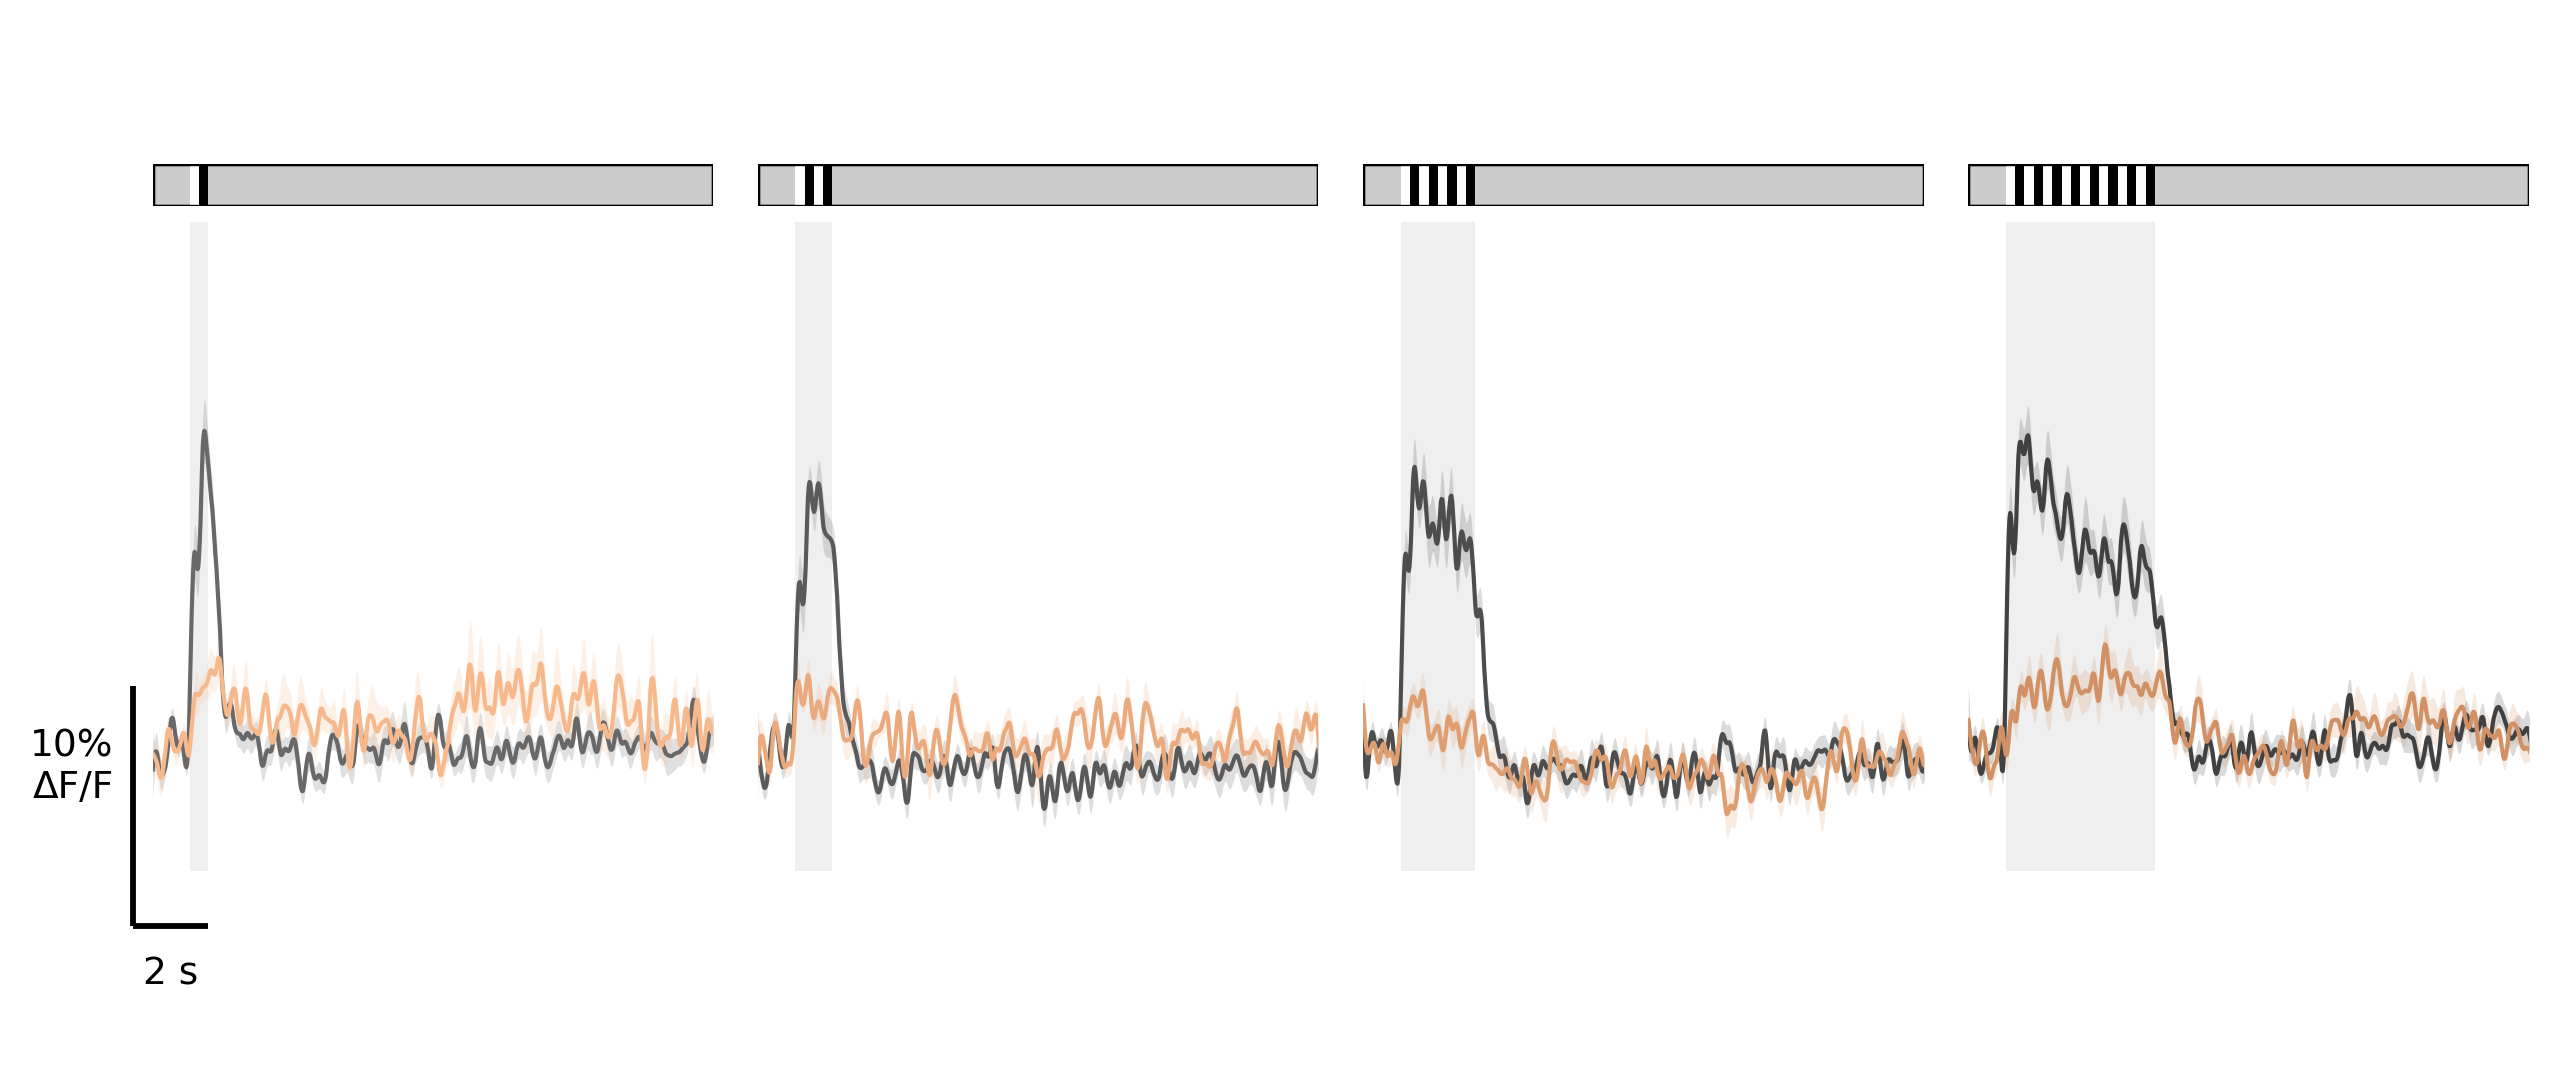

In [75]:
fig, axes = plot_csv_genotypes_overlay_all_stim_durations(
    plot_df,
    sensor="iachsnfr2",
    genotype_order=("CTR", "TNT"),
    colors=genotype_colors_ach,
    ylim=(-0.05, 0.22),
    xlim = (0, 15),
    show_legend=False,
    title=" ",
    wspace=0.08,
    lighten_shortest=0.15
)

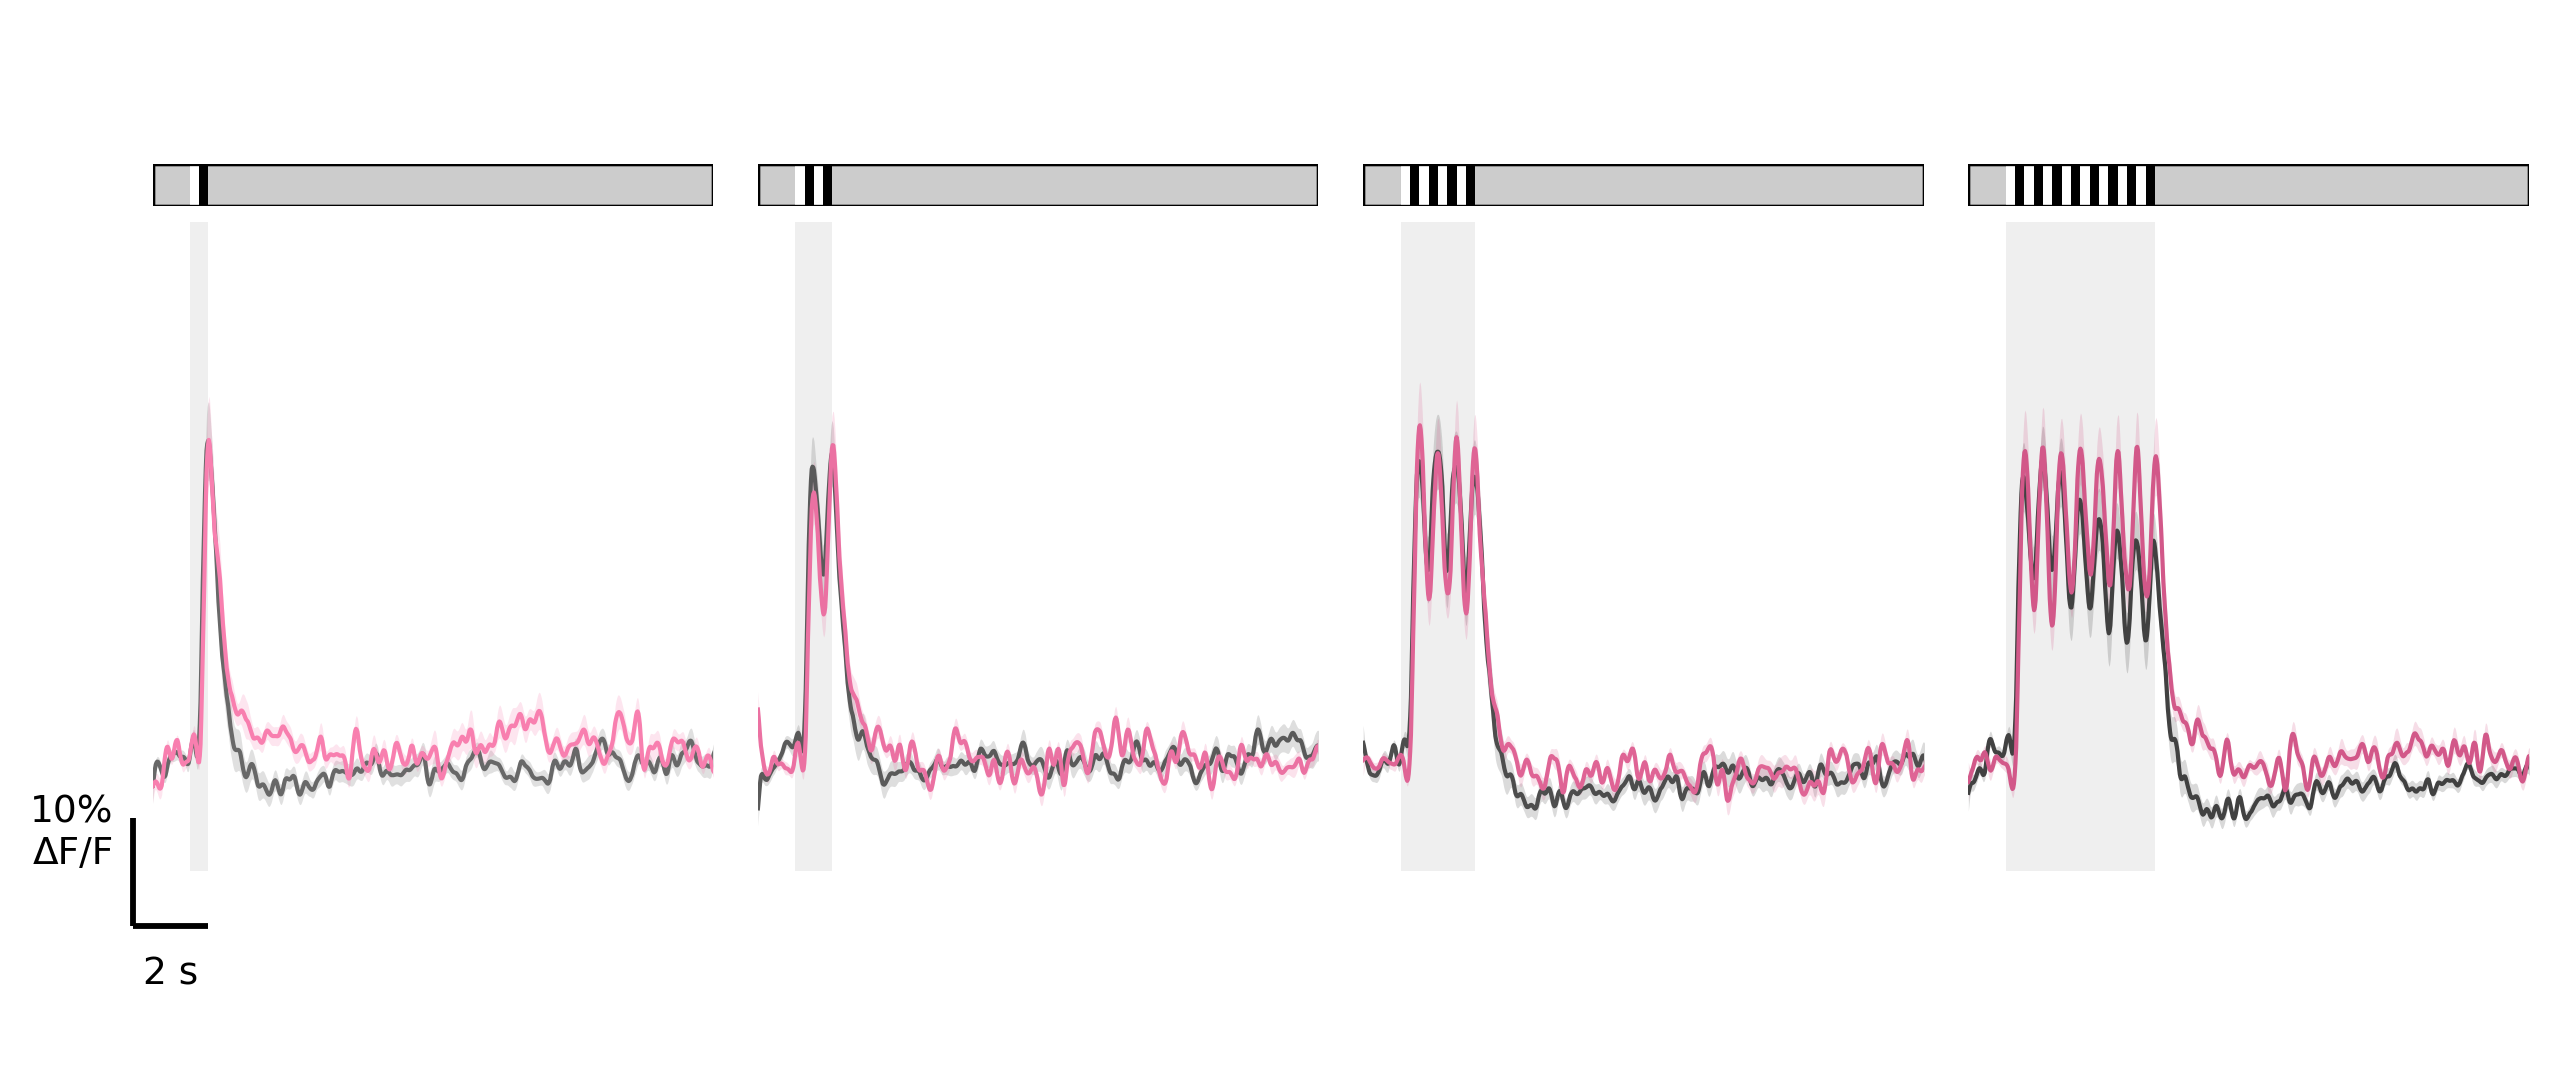

In [76]:
fig, axes = plot_csv_genotypes_overlay_all_stim_durations(
    plot_df,
    sensor="ca",
    genotype_order=("CTR", "TNT"),
    colors=genotype_colors_ca,
    ylim=(-0.1, 0.5),
    xlim = (0, 15),
    show_legend=False,
    title=" ",
    wspace=0.08,
    lighten_shortest=0.15
)